# 파이썬 머신러닝 완벽가이드 — 5장 회귀 (2)

ESAA YB · ch5.6~5.8 개념 필사

- **5.6** 규제 선형 모델 — 릿지, 라쏘, 엘라스틱넷
- **5.7** 로지스틱 회귀
- **5.8** 회귀 트리

출처: 저자 깃허브 [wikibook/pymldg-rev](https://github.com/wikibook/pymldg-rev) 5장

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

`load_boston`은 sklearn 1.2에서 제거됐다. 지난주와 같은 방식으로 OpenML에서
같은 데이터를 받아 동일한 인터페이스를 만들어 둔다.

In [2]:
# sklearn 1.2부터 load_boston이 제거되어 OpenML에서 같은 데이터를 받아온다.
from sklearn.datasets import fetch_openml

_b = fetch_openml(name='boston', version=1, as_frame=True, parser='auto')

class _Boston:
    data = _b.data.astype(float).values
    target = _b.target.astype(float).values
    feature_names = np.array(_b.data.columns)

def load_boston():
    return _Boston()

print('보스턴 데이터:', _Boston.data.shape)

보스턴 데이터: (506, 13)


## 5.6 규제 선형 모델 — 릿지, 라쏘, 엘라스틱넷

지금까지의 선형 회귀는 **RSS만 최소화**했다. 그런데 RSS만 줄이려 들면 학습 데이터에
지나치게 맞춰지면서 **회귀 계수가 커진다.** 계수가 크다는 것은 입력이 조금만 달라져도
예측이 크게 흔들린다는 뜻이고, 그게 과적합이다.

그래서 비용 함수에 **계수 크기에 대한 벌점**을 더한다.

$$\text{비용} = RSS(W) + \alpha \lVert W \rVert$$

- $\alpha$가 **0**이면 벌점이 사라져 일반 선형 회귀와 같다.
- $\alpha$가 **커지면** 계수를 작게 만드는 쪽이 유리해져 과적합이 줄어든다.
- $\alpha$가 **너무 커지면** 계수가 전부 0에 가까워져 과소적합이 된다.

즉 $\alpha$는 **학습 데이터에 맞추는 것과 계수를 작게 유지하는 것 사이의 저울**이다.

| 모델 | 규제 | 계수에 일어나는 일 |
|---|---|---|
| 릿지(Ridge) | L2 — 계수의 **제곱** 합 | 큰 계수를 작게 줄인다. **0이 되지는 않는다** |
| 라쏘(Lasso) | L1 — 계수의 **절댓값** 합 | 영향이 작은 계수를 **0으로 만든다** → 변수 선택 효과 |
| 엘라스틱넷 | L2 + L1 | 둘을 섞는다. `l1_ratio`로 비중 조절 |

### 릿지 회귀

In [3]:
# 앞의 LinearRegression예제에서 분할한 feature 데이터 셋인 X_data과 Target 데이터 셋인 Y_target 데이터셋을 그대로 이용 
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

# boston 데이타셋 로드
boston = load_boston()

# boston 데이타셋 DataFrame 변환 
bostonDF = pd.DataFrame(boston.data , columns = boston.feature_names)

# boston dataset의 target array는 주택 가격임. 이를 PRICE 컬럼으로 DataFrame에 추가함. 
bostonDF['PRICE'] = boston.target
print('Boston 데이타셋 크기 :',bostonDF.shape)

y_target = bostonDF['PRICE']
X_data = bostonDF.drop(['PRICE'],axis=1,inplace=False)


ridge = Ridge(alpha = 10)
neg_mse_scores = cross_val_score(ridge, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
rmse_scores  = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)
print(' 5 folds 의 개별 Negative MSE scores: ', np.round(neg_mse_scores, 3))
print(' 5 folds 의 개별 RMSE scores : ', np.round(rmse_scores,3))
print(' 5 folds 의 평균 RMSE : {0:.3f} '.format(avg_rmse))

Boston 데이타셋 크기 : (506, 14)
 5 folds 의 개별 Negative MSE scores:  [-11.422 -24.294 -28.144 -74.599 -28.517]
 5 folds 의 개별 RMSE scores :  [3.38  4.929 5.305 8.637 5.34 ]
 5 folds 의 평균 RMSE : 5.518 


**alpha값을 0 , 0.1 , 1 , 10 , 100 으로 변경하면서 RMSE 측정**

In [4]:
# Ridge에 사용될 alpha 파라미터의 값들을 정의
alphas = [0 , 0.1 , 1 , 10 , 100]

# alphas list 값을 iteration하면서 alpha에 따른 평균 rmse 구함.
for alpha in alphas :
    ridge = Ridge(alpha = alpha)
    
    #cross_val_score를 이용하여 5 fold의 평균 RMSE 계산
    neg_mse_scores = cross_val_score(ridge, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print('alpha {0} 일 때 5 folds 의 평균 RMSE : {1:.3f} '.format(alpha,avg_rmse))

alpha 0 일 때 5 folds 의 평균 RMSE : 5.829 
alpha 0.1 일 때 5 folds 의 평균 RMSE : 5.788 


alpha 1 일 때 5 folds 의 평균 RMSE : 5.653 


alpha 10 일 때 5 folds 의 평균 RMSE : 5.518 
alpha 100 일 때 5 folds 의 평균 RMSE : 5.330 


`alpha=0`일 때가 일반 선형 회귀다. 여기서는 alpha를 100까지 키우는 동안
RMSE가 5.829에서 5.330까지 **계속 줄어든다.** 규제가 아직 과하지 않다는 뜻이다.

alpha를 더 키우면 언젠가는 계수가 지나치게 눌려 다시 나빠진다. 뒤에 나오는 라쏘와
엘라스틱넷에서는 그 전환점이 이 범위 안에 들어와서, **RMSE가 줄다가 다시 늘어나는 것**을
직접 볼 수 있다.

**각 alpha에 따른 회귀 계수 값을 시각화. 각 alpha값 별로 plt.subplots로 맷플롯립 축 생성**

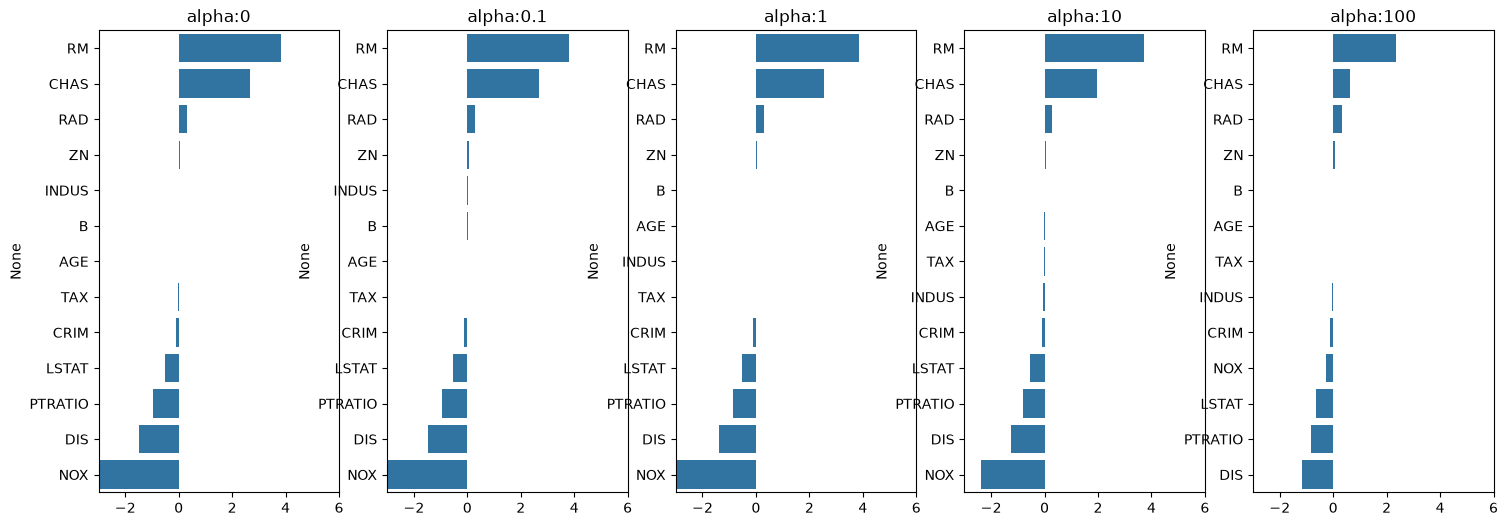

In [5]:
# 각 alpha에 따른 회귀 계수 값을 시각화하기 위해 5개의 열로 된 맷플롯립 축 생성  
fig , axs = plt.subplots(figsize=(18,6) , nrows=1 , ncols=5)
# 각 alpha에 따른 회귀 계수 값을 데이터로 저장하기 위한 DataFrame 생성  
coeff_df = pd.DataFrame()

# alphas 리스트 값을 차례로 입력해 회귀 계수 값 시각화 및 데이터 저장. pos는 axis의 위치 지정
for pos , alpha in enumerate(alphas) :
    ridge = Ridge(alpha = alpha)
    ridge.fit(X_data , y_target)
    # alpha에 따른 피처별 회귀 계수를 Series로 변환하고 이를 DataFrame의 컬럼으로 추가.  
    coeff = pd.Series(data=ridge.coef_ , index=X_data.columns )
    colname='alpha:'+str(alpha)
    coeff_df[colname] = coeff
    # 막대 그래프로 각 alpha 값에서의 회귀 계수를 시각화. 회귀 계수값이 높은 순으로 표현
    coeff = coeff.sort_values(ascending=False)
    axs[pos].set_title(colname)
    axs[pos].set_xlim(-3,6)
    sns.barplot(x=coeff.values , y=coeff.index, ax=axs[pos])

# for 문 바깥에서 맷플롯립의 show 호출 및 alpha에 따른 피처별 회귀 계수를 DataFrame으로 표시
plt.show()



alpha가 커질수록 막대가 전반적으로 짧아진다. 계수가 0 쪽으로 눌리고 있다는 뜻이다.
다만 **완전히 0이 되는 계수는 없다.** L2 규제는 계수를 줄이기만 하고 없애지는 않는다.

**alpha 값에 따른 컬럼별 회귀계수 출력**

In [6]:
ridge_alphas = [0 , 0.1 , 1 , 10 , 100]
sort_column = 'alpha:'+str(ridge_alphas[0])
coeff_df.sort_values(by=sort_column, ascending=False)

,alpha:0,alpha:0.1,alpha:1,alpha:10,alpha:100
RM,3.809865,3.818233,3.854000,3.702272,2.334536
CHAS,2.686734,2.670019,2.552393,1.952021,0.638335
RAD,0.306049,0.303515,0.290142,0.279596,0.315358
ZN,0.046420,0.046572,0.047443,0.049579,0.054496
INDUS,0.020559,0.015999,-0.008805,-0.042962,-0.052826
B,0.009312,0.009368,0.009673,0.010037,0.009393
AGE,0.000692,-0.000269,-0.005415,-0.010707,0.001212
TAX,-0.012335,-0.012421,-0.012912,-0.013993,-0.015856
CRIM,-0.108011,-0.107474,-0.104595,-0.101435,-0.102202
LSTAT,-0.524758,-0.525966,-0.533343,-0.559366,-0.660764


`NOX`를 보면 alpha=0에서 -17.8이던 계수가 alpha=100에서 -0.26까지 줄어든다.
규제가 가장 크게 작용한 변수다. 반면 `CRIM`(-0.108 → -0.102)이나 `B`(0.009 → 0.009)처럼
원래 계수가 작던 변수는 거의 그대로다. **L2 규제는 큰 계수부터 깎는다.**

### 라쏘 회귀

In [7]:
from sklearn.linear_model import Lasso, ElasticNet

# alpha값에 따른 회귀 모델의 폴드 평균 RMSE를 출력하고 회귀 계수값들을 DataFrame으로 반환 
def get_linear_reg_eval(model_name, params=None, X_data_n=None, y_target_n=None, 
                        verbose=True, return_coeff=True):
    coeff_df = pd.DataFrame()
    if verbose : print('####### ', model_name , '#######')
    for param in params:
        if model_name =='Ridge': model = Ridge(alpha=param)
        elif model_name =='Lasso': model = Lasso(alpha=param)
        elif model_name =='ElasticNet': model = ElasticNet(alpha=param, l1_ratio=0.7)
        neg_mse_scores = cross_val_score(model, X_data_n, 
                                             y_target_n, scoring="neg_mean_squared_error", cv = 5)
        avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
        print('alpha {0}일 때 5 폴드 세트의 평균 RMSE: {1:.3f} '.format(param, avg_rmse))
        # cross_val_score는 evaluation metric만 반환하므로 모델을 다시 학습하여 회귀 계수 추출
        
        model.fit(X_data_n , y_target_n)
        if return_coeff:
            # alpha에 따른 피처별 회귀 계수를 Series로 변환하고 이를 DataFrame의 컬럼으로 추가. 
            coeff = pd.Series(data=model.coef_ , index=X_data_n.columns )
            colname='alpha:'+str(param)
            coeff_df[colname] = coeff
    
    return coeff_df
# end of get_linear_regre_eval

In [8]:
# 라쏘에 사용될 alpha 파라미터의 값들을 정의하고 get_linear_reg_eval() 함수 호출
lasso_alphas = [ 0.07, 0.1, 0.5, 1, 3]
coeff_lasso_df =get_linear_reg_eval('Lasso', params=lasso_alphas, X_data_n=X_data, y_target_n=y_target)

#######  Lasso #######
alpha 0.07일 때 5 폴드 세트의 평균 RMSE: 5.612 
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.615 
alpha 0.5일 때 5 폴드 세트의 평균 RMSE: 5.669 
alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.776 
alpha 3일 때 5 폴드 세트의 평균 RMSE: 6.189 


In [9]:
print(lasso_alphas)

[0.07, 0.1, 0.5, 1, 3]


In [10]:
# 반환된 coeff_lasso_df를 첫번째 컬럼순으로 내림차순 정렬하여 회귀계수 DataFrame출력
sort_column = 'alpha:'+str(lasso_alphas[0])
coeff_lasso_df.sort_values(by=sort_column, ascending=False)

,alpha:0.07,alpha:0.1,alpha:0.5,alpha:1,alpha:3
RM,3.789725,3.703202,2.498212,0.949811,0.000000
CHAS,1.434343,0.955190,0.000000,0.000000,0.000000
RAD,0.270936,0.274707,0.277451,0.264206,0.061864
ZN,0.049059,0.049211,0.049544,0.049165,0.037231
B,0.010248,0.010249,0.009469,0.008247,0.006510
NOX,-0.000000,-0.000000,-0.000000,-0.000000,0.000000
AGE,-0.011706,-0.010037,0.003604,0.020910,0.042495
TAX,-0.014290,-0.014570,-0.015442,-0.015212,-0.008602
INDUS,-0.042120,-0.036619,-0.005253,-0.000000,-0.000000
CRIM,-0.098193,-0.097894,-0.083289,-0.063437,-0.000000


라쏘는 릿지와 달리 **계수가 정확히 0이 되는 변수가 생긴다.** 위 표에서 `NOX`는
가장 약한 규제(alpha=0.07)에서 이미 0이고, `CHAS`는 alpha=0.5에서, `INDUS`는 alpha=1에서
0이 된다. alpha=3까지 가면 13개 중 7개만 살아남는다.

0이 됐다는 것은 그 변수를 **아예 쓰지 않는다**는 뜻이다. 그래서 라쏘는 규제인 동시에
**변수 선택기**다. 어떤 변수를 뺄지 사람이 고르는 대신 **데이터가 정하게 하는** 방식이다.

RMSE도 릿지와 다르게 움직인다. alpha=0.07에서 5.612로 가장 낮고, 그 뒤로는
5.615 → 5.669 → 5.776 → 6.189으로 계속 나빠진다. **규제가 과해지는 지점이 이 범위
안에 들어와 있다.** 릿지의 L2는 계수를 줄이기만 하지만, 라쏘의 L1은 변수를 아예
버리기 때문에 과해질 때의 손해가 더 빨리 나타난다.

### 엘라스틱넷 회귀

In [11]:
# 엘라스틱넷에 사용될 alpha 파라미터의 값들을 정의하고 get_linear_reg_eval() 함수 호출
# l1_ratio는 0.7로 고정
elastic_alphas = [ 0.07, 0.1, 0.5, 1, 3]
coeff_elastic_df =get_linear_reg_eval('ElasticNet', params=elastic_alphas,
                                      X_data_n=X_data, y_target_n=y_target)

#######  ElasticNet #######
alpha 0.07일 때 5 폴드 세트의 평균 RMSE: 5.542 


alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.526 
alpha 0.5일 때 5 폴드 세트의 평균 RMSE: 5.467 
alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.597 
alpha 3일 때 5 폴드 세트의 평균 RMSE: 6.068 


In [12]:
# 반환된 coeff_elastic_df를 첫번째 컬럼순으로 내림차순 정렬하여 회귀계수 DataFrame출력
sort_column = 'alpha:'+str(elastic_alphas[0])
coeff_elastic_df.sort_values(by=sort_column, ascending=False)

,alpha:0.07,alpha:0.1,alpha:0.5,alpha:1,alpha:3
RM,3.574162,3.414154,1.918419,0.938789,0.000000
CHAS,1.330724,0.979706,0.000000,0.000000,0.000000
RAD,0.278880,0.283443,0.300761,0.289299,0.146846
ZN,0.050107,0.050617,0.052878,0.052136,0.038268
B,0.010122,0.010067,0.009114,0.008320,0.007020
AGE,-0.010116,-0.008276,0.007760,0.020348,0.043446
TAX,-0.014522,-0.014814,-0.016046,-0.016218,-0.011417
INDUS,-0.044855,-0.042719,-0.023252,-0.000000,-0.000000
CRIM,-0.099468,-0.099213,-0.089070,-0.073577,-0.019058
NOX,-0.175072,-0.000000,-0.000000,-0.000000,-0.000000


엘라스틱넷은 alpha=0.5에서 RMSE 5.467로 가장 낮다. 같은 alpha에서 라쏘(5.669)보다 낫다.

L1만 쓰면 **상관이 높은 변수들 중 하나만 남기고 나머지를 0으로** 만드는 경향이 있다.
L2를 섞으면 그런 변수들을 한꺼번에 버리지 않고 조금씩 함께 남긴다. `l1_ratio`가 그 비중을
정한다 — 여기서는 0.7이니 L1이 7, L2가 3이다. 실제로 alpha=0.5에서 라쏘는 `CHAS`와 `NOX`를
0으로 만들었지만, 엘라스틱넷은 `RM`을 1.92로 라쏘(2.50)보다 작게 누르는 쪽을 택했다.

### 선형 회귀 모델을 위한 데이터 변환

In [13]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures

# method는 표준 정규 분포 변환(Standard), 최대값/최소값 정규화(MinMax), 로그변환(Log) 결정
# p_degree는 다향식 특성을 추가할 때 적용. p_degree는 2이상 부여하지 않음. 
def get_scaled_data(method='None', p_degree=None, input_data=None):
    if method == 'Standard':
        scaled_data = StandardScaler().fit_transform(input_data)
    elif method == 'MinMax':
        scaled_data = MinMaxScaler().fit_transform(input_data)
    elif method == 'Log':
        scaled_data = np.log1p(input_data)
    else:
        scaled_data = input_data

    if p_degree != None:
        scaled_data = PolynomialFeatures(degree=p_degree, 
                                         include_bias=False).fit_transform(scaled_data)
    
    return scaled_data

In [14]:
# Ridge의 alpha값을 다르게 적용하고 다양한 데이터 변환방법에 따른 RMSE 추출. 
alphas = [0.1, 1, 10, 100]
#변환 방법은 모두 6개, 원본 그대로, 표준정규분포, 표준정규분포+다항식 특성
# 최대/최소 정규화, 최대/최소 정규화+다항식 특성, 로그변환 
scale_methods=[(None, None), ('Standard', None), ('Standard', 2), 
               ('MinMax', None), ('MinMax', 2), ('Log', None)]
for scale_method in scale_methods:
    X_data_scaled = get_scaled_data(method=scale_method[0], p_degree=scale_method[1], 
                                    input_data=X_data)
    print(X_data_scaled.shape, X_data.shape)
    print('\n## 변환 유형:{0}, Polynomial Degree:{1}'.format(scale_method[0], scale_method[1]))
    get_linear_reg_eval('Ridge', params=alphas, X_data_n=X_data_scaled, 
                        y_target_n=y_target, verbose=False, return_coeff=False)

(506, 13) (506, 13)

## 변환 유형:None, Polynomial Degree:None


alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.788 


alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.653 
alpha 10일 때 5 폴드 세트의 평균 RMSE: 5.518 
alpha 100일 때 5 폴드 세트의 평균 RMSE: 5.330 
(506, 13) (506, 13)

## 변환 유형:Standard, Polynomial Degree:None
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.826 


alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.803 


alpha 10일 때 5 폴드 세트의 평균 RMSE: 5.637 
alpha 100일 때 5 폴드 세트의 평균 RMSE: 5.421 
(506, 104) (506, 13)

## 변환 유형:Standard, Polynomial Degree:2


alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 8.827 
alpha 1일 때 5 폴드 세트의 평균 RMSE: 6.871 
alpha 10일 때 5 폴드 세트의 평균 RMSE: 5.485 
alpha 100일 때 5 폴드 세트의 평균 RMSE: 4.634 
(506, 13) (506, 13)

## 변환 유형:MinMax, Polynomial Degree:None
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.764 
alpha 1일 때 5 폴드 세트의 평균 RMSE: 5.465 
alpha 10일 때 5 폴드 세트의 평균 RMSE: 5.754 
alpha 100일 때 5 폴드 세트의 평균 RMSE: 7.635 
(506, 104) (506, 13)

## 변환 유형:MinMax, Polynomial Degree:2


alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 5.298 
alpha 1일 때 5 폴드 세트의 평균 RMSE: 4.323 
alpha 10일 때 5 폴드 세트의 평균 RMSE: 5.185 
alpha 100일 때 5 폴드 세트의 평균 RMSE: 6.538 
(506, 13) (506, 13)

## 변환 유형:Log, Polynomial Degree:None
alpha 0.1일 때 5 폴드 세트의 평균 RMSE: 4.770 


alpha 1일 때 5 폴드 세트의 평균 RMSE: 4.676 
alpha 10일 때 5 폴드 세트의 평균 RMSE: 4.836 
alpha 100일 때 5 폴드 세트의 평균 RMSE: 6.241 


## 5.7 로지스틱 회귀

이름은 회귀지만 **분류에 쓰는 모델**이다. 선형 회귀처럼 $w_0 + w_1x_1 + \dots$를 계산한 뒤,
그 값을 **시그모이드 함수**에 넣어 0과 1 사이로 눌러서 확률로 해석한다.

$$p = \frac{1}{1 + e^{-(w_0 + w_1x_1 + \dots)}}$$

선형 회귀는 출력이 $-\infty$에서 $+\infty$까지 열려 있어 확률로 쓸 수 없다. 시그모이드가
그 범위를 (0, 1)로 접어 넣어 주기 때문에 분류가 가능해진다.

**입력값의 스케일에 민감하다.** 계수와 특성값을 곱해 더하는 구조라, 단위가 큰 변수가
그대로 큰 영향을 갖는다. 그래서 아래 코드도 `StandardScaler`를 먼저 적용한다.
(트리 모델에서는 필요 없던 작업이다.)

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

cancer = load_breast_cancer()

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# StandardScaler( )로 평균이 0, 분산 1로 데이터 분포도 변환
scaler = StandardScaler()
data_scaled = scaler.fit_transform(cancer.data)

X_train , X_test, y_train , y_test = train_test_split(data_scaled, cancer.target, test_size=0.3, random_state=0)

In [17]:
from sklearn.metrics import accuracy_score, roc_auc_score

# 로지스틱 회귀를 이용하여 학습 및 예측 수행. 
lr_clf = LogisticRegression()
lr_clf.fit(X_train, y_train)
lr_preds = lr_clf.predict(X_test)

# accuracy와 roc_auc 측정
print('accuracy: {:0.3f}'.format(accuracy_score(y_test, lr_preds)))
print('roc_auc: {:0.3f}'.format(roc_auc_score(y_test , lr_preds)))

accuracy: 0.977
roc_auc: 0.972


`penalty`는 로지스틱 회귀에도 규제가 들어간다는 뜻이다. 그런데 **solver마다 지원하는
규제가 다르다.** 기본값인 `lbfgs`는 L1을 지원하지 않아서, 책의 코드를 그대로 돌리면
L1 조합이 전부 실패한다. `solver`를 함께 탐색 대상에 넣어 `liblinear`가 L1을 맡도록 한다.

In [18]:
from sklearn.model_selection import GridSearchCV

# 책의 코드에 solver를 추가. lbfgs는 L2만, liblinear는 L1·L2를 모두 지원한다.
params = {'solver': ['liblinear', 'lbfgs'],
          'penalty': ['l2', 'l1'],
          'C': [0.01, 0.1, 1, 5, 10]}

grid_clf = GridSearchCV(lr_clf, param_grid=params, scoring='accuracy', cv=3)
grid_clf.fit(data_scaled, cancer.target)
print('최적 하이퍼 파라미터:{0}, 최적 평균 정확도:{1:.3f}'.format(grid_clf.best_params_,
                                                  grid_clf.best_score_))

최적 하이퍼 파라미터:{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}, 최적 평균 정확도:0.979


`C`는 **규제 강도의 역수**다. 릿지·라쏘의 `alpha`와 방향이 반대라서,
`C`가 작을수록 규제가 세진다. 둘을 헷갈리기 쉬운 지점이다.

## 5.8 회귀 트리

트리로도 회귀를 할 수 있다. 분류 트리는 리프 노드의 **최빈 클래스**를 답으로 내놓는데,
회귀 트리는 리프 노드에 속한 데이터의 **평균값**을 내놓는다. 그게 전부다.

여기서 회귀 트리의 성질이 바로 따라 나온다. **예측값이 리프 개수만큼의 값만 가질 수 있다.**
그래서 예측선이 직선이 아니라 **계단 모양**이 된다. 뒤의 그래프에서 직접 확인한다.

In [19]:
# from sklearn.datasets import load_boston  (위 셀에서 대체)
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

# 보스턴 데이터 세트 로드
boston = load_boston()
bostonDF = pd.DataFrame(boston.data, columns = boston.feature_names)

bostonDF['PRICE'] = boston.target
y_target = bostonDF['PRICE']
X_data = bostonDF.drop(['PRICE'], axis=1,inplace=False)

rf = RandomForestRegressor(random_state=0, n_estimators=1000)
neg_mse_scores = cross_val_score(rf, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
rmse_scores  = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

print(' 5 교차 검증의 개별 Negative MSE scores: ', np.round(neg_mse_scores, 2))
print(' 5 교차 검증의 개별 RMSE scores : ', np.round(rmse_scores, 2))
print(' 5 교차 검증의 평균 RMSE : {0:.3f} '.format(avg_rmse))


 5 교차 검증의 개별 Negative MSE scores:  [ -7.88 -13.14 -20.57 -46.23 -18.88]
 5 교차 검증의 개별 RMSE scores :  [2.81 3.63 4.54 6.8  4.34]
 5 교차 검증의 평균 RMSE : 4.423 


In [20]:
def get_model_cv_prediction(model, X_data, y_target):
    neg_mse_scores = cross_val_score(model, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
    rmse_scores  = np.sqrt(-1 * neg_mse_scores)
    avg_rmse = np.mean(rmse_scores)
    print('##### ',model.__class__.__name__ , ' #####')
    print(' 5 교차 검증의 평균 RMSE : {0:.3f} '.format(avg_rmse))

In [21]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

dt_reg = DecisionTreeRegressor(random_state=0, max_depth=4)
rf_reg = RandomForestRegressor(random_state=0, n_estimators=1000)
gb_reg = GradientBoostingRegressor(random_state=0, n_estimators=1000)
xgb_reg = XGBRegressor(n_estimators=1000)
lgb_reg = LGBMRegressor(n_estimators=1000, verbose=-1)  # 학습 로그가 수백 줄 나와서 끔

# 트리 기반의 회귀 모델을 반복하면서 평가 수행 
models = [dt_reg, rf_reg, gb_reg, xgb_reg, lgb_reg]
for model in models:  
    get_model_cv_prediction(model, X_data, y_target)

#####  DecisionTreeRegressor  #####
 5 교차 검증의 평균 RMSE : 5.978 


#####  RandomForestRegressor  #####
 5 교차 검증의 평균 RMSE : 4.423 


#####  GradientBoostingRegressor  #####
 5 교차 검증의 평균 RMSE : 4.269 


#####  XGBRegressor  #####
 5 교차 검증의 평균 RMSE : 4.968 


#####  LGBMRegressor  #####
 5 교차 검증의 평균 RMSE : 4.646 


트리 기반 회귀 모델 다섯 개의 RMSE다. 단일 결정 트리가 가장 나쁘고,
여러 트리를 묶은 앙상블(랜덤 포레스트·GBM·XGBoost·LightGBM)이 크게 낫다.
**분류에서 봤던 것과 같은 구도**가 회귀에서도 그대로 나타난다.

<Axes: xlabel='None', ylabel='None'>

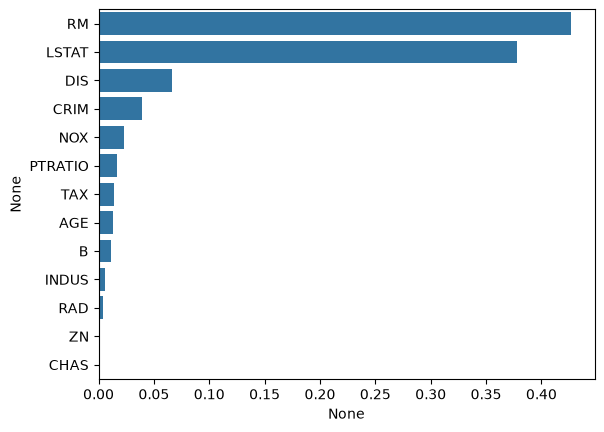

In [22]:
import seaborn as sns
%matplotlib inline

rf_reg = RandomForestRegressor(n_estimators=1000)

# 앞 예제에서 만들어진 X_data, y_target 데이터 셋을 적용하여 학습합니다.   
rf_reg.fit(X_data, y_target)

feature_series = pd.Series(data=rf_reg.feature_importances_, index=X_data.columns )
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x= feature_series, y=feature_series.index)


`RM`(방 개수)과 `LSTAT`(하위 계층 비율) 두 변수가 중요도의 대부분을 차지한다.
회귀 트리도 분류 트리처럼 `feature_importances_`로 어떤 변수를 썼는지 볼 수 있다.

(100, 2)


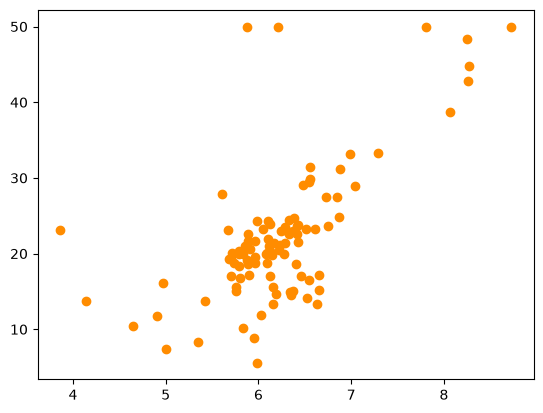

In [23]:
import matplotlib.pyplot as plt
%matplotlib inline

bostonDF_sample = bostonDF[['RM','PRICE']]
bostonDF_sample = bostonDF_sample.sample(n=100,random_state=0)
print(bostonDF_sample.shape)
plt.figure()
plt.scatter(bostonDF_sample.RM , bostonDF_sample.PRICE,c="darkorange")

In [24]:
import numpy as np
from sklearn.linear_model import LinearRegression

# 선형 회귀와 결정 트리 기반의 Regressor 생성. DecisionTreeRegressor의 max_depth는 각각 2, 7
lr_reg = LinearRegression()
rf_reg2 = DecisionTreeRegressor(max_depth=2)
rf_reg7 = DecisionTreeRegressor(max_depth=7)

# 실제 예측을 적용할 테스트용 데이터 셋을 4.5 ~ 8.5 까지 100개 데이터 셋 생성. 
X_test = np.arange(4.5, 8.5, 0.04).reshape(-1, 1)

# 보스턴 주택가격 데이터에서 시각화를 위해 피처는 RM만, 그리고 결정 데이터인 PRICE 추출
X_feature = bostonDF_sample['RM'].values.reshape(-1,1)
y_target = bostonDF_sample['PRICE'].values.reshape(-1,1)

# 학습과 예측 수행. 
lr_reg.fit(X_feature, y_target)
rf_reg2.fit(X_feature, y_target)
rf_reg7.fit(X_feature, y_target)

pred_lr = lr_reg.predict(X_test)
pred_rf2 = rf_reg2.predict(X_test)
pred_rf7 = rf_reg7.predict(X_test)


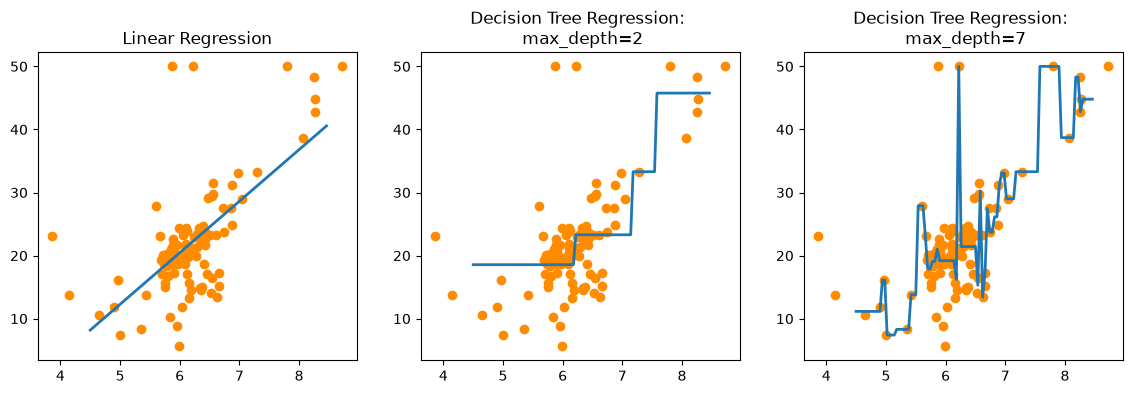

In [25]:
fig , (ax1, ax2, ax3) = plt.subplots(figsize=(14,4), ncols=3)

# X축값을 4.5 ~ 8.5로 변환하며 입력했을 때, 선형 회귀와 결정 트리 회귀 예측 선 시각화
# 선형 회귀로 학습된 모델 회귀 예측선 
ax1.set_title('Linear Regression')
ax1.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
ax1.plot(X_test, pred_lr,label="linear", linewidth=2 )

# DecisionTreeRegressor의 max_depth를 2로 했을 때 회귀 예측선 
ax2.set_title('Decision Tree Regression: \n max_depth=2')
ax2.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
ax2.plot(X_test, pred_rf2, label="max_depth:3", linewidth=2 )

# DecisionTreeRegressor의 max_depth를 7로 했을 때 회귀 예측선 
ax3.set_title('Decision Tree Regression: \n max_depth=7')
ax3.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c="darkorange")
ax3.plot(X_test, pred_rf7, label="max_depth:7", linewidth=2)

**왼쪽이 선형 회귀, 가운데와 오른쪽이 회귀 트리다.**

선형 회귀의 예측선은 **하나의 직선**이다. 반면 회귀 트리는 **계단**이다. `max_depth=2`면
리프가 적어 계단이 몇 칸 안 되고, `max_depth=7`이면 리프가 많아져 계단이 잘게 쪼개진다.

오른쪽 그래프가 과적합을 눈으로 보여 준다. 점 하나하나를 따라가려고 계단이 지나치게
잘게 나뉘어 있다. **학습 데이터의 잡음까지 그대로 외운 상태**다.

계단 모양에서 따라오는 한계가 하나 더 있다. 회귀 트리는 **학습 데이터의 범위 밖을
예측하지 못한다.** 리프의 평균값만 내놓기 때문에, 본 적 없는 구간이 들어오면
가장 가까운 리프의 값을 그대로 반복할 뿐이다. 선형 회귀는 직선을 늘려 외삽할 수 있다.

## 느낀 점

**규제는 결국 계수를 작게 만드는 일이었다.** 과적합을 막는다는 설명만 들었을 때는
추상적이었는데, alpha를 키우면서 막대그래프가 짧아지는 걸 보니 무슨 일이 일어나는지
분명해졌다. alpha가 0이면 일반 선형 회귀, 무한대로 가면 계수가 전부 0에 수렴한다는
양 끝을 잡고 나니 중간값이 왜 필요한지도 이해됐다.

**라쏘가 변수를 0으로 만든다는 게 미니프로젝트와 겹쳐 보였다.** 저는 변수 간 상관 EDA를
맡으면서 품질과 상관이 약한 변수 일곱 개를 빼고 돌려봤는데, 오히려 2.6%p가 떨어졌다.
상관계수를 기준으로 사람이 고른 게 틀렸던 것이다. 라쏘는 그 판단을 **비용 함수 안에서
데이터가 하게** 만든다. 다만 라쏘가 쓸 수 있었던 건 선형 모델이었기 때문이고,
우리가 쓴 트리 모델에는 그런 장치가 없어서 결국 하나씩 빼 보는 수밖에 없었다.

**로지스틱 회귀가 왜 미니프로젝트에서 밀렸는지 알겠다.** 와인 데이터에서 로지스틱 회귀는
0.5417이었고 트리는 0.6785였다. 14%p 차이가 났다. 로지스틱 회귀는 결국 변수들의
**가중합 하나**를 시그모이드에 넣는 구조라, 변수끼리 조합해서 생기는 관계를 담지 못한다.
와인에서는 도수와 밀도가 같이 움직여야 설명되는 부분이 있었는데 그걸 못 잡은 것이다.

**회귀 트리의 계단 그래프가 제일 인상 깊었다.** 트리는 리프의 평균을 내놓으니 예측값의
가짓수가 리프 개수로 제한된다. `max_depth=7` 그래프에서 계단이 잘게 쪼개진 모습이
과적합 그 자체였다. 미니프로젝트에서 XGBoost의 깊이를 4에서 10까지 늘리자 교차검증
점수가 계속 올랐던 것도 같은 현상이었다. 깊어질수록 리프가 잘게 나뉘고, 결국 중복된
행을 각자의 리프에 하나씩 담아 외운 것이다. 그때는 점수가 오르니 좋은 줄 알았는데
이제 보니 이 계단이 잘게 부서지고 있었던 셈이다.

**데이터 변환이 선형 모델에서만 의미가 있다는 것도 정리됐다.** 5.6 마지막에서 표준화·
정규화·로그 변환에 따라 릿지의 RMSE가 눈에 띄게 달라졌다. 반면 미니프로젝트에서는
MinMax 스케일링을 적용해도 트리 모델의 점수가 0.0002밖에 안 움직였다. 트리는 값의
**순서**만 보기 때문에 단조 변환에 결과가 바뀌지 않는다. 같은 전처리가 모델에 따라
필수이기도 하고 무의미하기도 하다는 걸 두 장에 걸쳐 확인했다.